
# Retail Sales Analysis: Identifying Revenue Trends & Business Opportunities

## Project Overview
This project analyzes retail sales data to identify revenue trends, profitability patterns, customer behavior, and business opportunities.

## Objectives
- Analyze overall sales and profitability.
- Identify profitable and loss-making product categories.
- Evaluate the relationship between discounts and profit.
- Explore monthly and yearly sales trends.
- Compare regional performance.
- Analyze customer contribution.
- Use SQL to perform business-focused queries.

## Tools & Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, SQLite, SQL, Jupyter Notebook.

## Dataset
Sample Superstore dataset containing order-level and product-level retail information.

# Retail Sales Analysis: Identifying Revenue Trends & Business Opportunities

## Project Overview
This project analyzes retail sales data to identify revenue trends, profitability patterns, customer behavior, and business opportunities.

## Objectives
- Analyze overall sales and profitability.
- Identify profitable and loss-making product categories.
- Evaluate the relationship between discounts and profit.
- Explore monthly and yearly sales trends.
- Compare regional performance.
- Analyze customer contribution.
- Use SQL to perform business-focused queries.

## Tools & Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, SQLite, SQL, Jupyter Notebook.

## Dataset
Sample Superstore dataset containing order-level and product-level retail information.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

from matplotlib.ticker import FuncFormatter

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

sns.set_theme(style='whitegrid')


In [2]:

df = pd.read_csv(
    'Sample - Superstore.csv',
    encoding='latin1'
)

df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


In [3]:

print("Dataset Shape:", df.shape)
print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Dataset Shape: (9994, 21)

Number of Rows: 9994
Number of Columns: 21


In [4]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994


## Data Cleaning & Validation

Before performing analysis, the dataset is checked for missing values, duplicate records, incorrect data types, and invalid values.


In [5]:

print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print(
    "\nDuplicate Rows (excluding Row ID):",
    df.drop(columns=['Row ID']).duplicated().sum()
)


Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Total Missing Values: 0

Duplicate Rows (excluding Row ID): 1


In [6]:

df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    format='%m/%d/%Y'
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'],
    format='%m/%d/%Y'
)

df['Postal Code'] = (
    df['Postal Code']
    .astype('Int64')
    .astype(str)
    .str.zfill(5)
)

print("Date conversion and Postal Code formatting completed.")


Date conversion and Postal Code formatting completed.


In [7]:

print("Invalid Ship Dates:",
      (df['Ship Date'] < df['Order Date']).sum())

print("Invalid Discounts:",
      (~df['Discount'].between(0, 1)).sum())

print("Invalid Quantities:",
      (df['Quantity'] <= 0).sum())


Invalid Ship Dates: 0
Invalid Discounts: 0
Invalid Quantities: 0



## Feature Engineering

New time-based features are extracted from Order Date to support monthly, quarterly, and yearly sales analysis.


In [8]:

df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Order Month Name'] = df['Order Date'].dt.month_name()
df['Order Quarter'] = df['Order Date'].dt.quarter

df['Shipping Days'] = (
    df['Ship Date'] - df['Order Date']
).dt.days

df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Month Name,Order Quarter,Shipping Days
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91,2016,11,November,4,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58,2016,11,November,4,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87,2016,6,June,2,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03,2015,10,October,4,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52,2015,10,October,4,7



## Key Business Performance Indicators

This section calculates the overall revenue, profit, order volume, customer count, quantity sold, and profit margin.


In [9]:

total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()
total_customers = df['Customer ID'].nunique()
total_quantity = df['Quantity'].sum()

profit_margin = (
    total_profit / total_sales
) * 100

kpi_summary = pd.DataFrame({
    'Metric': [
        'Total Sales',
        'Total Profit',
        'Total Orders',
        'Total Customers',
        'Total Quantity',
        'Profit Margin'
    ],
    'Value': [
        total_sales,
        total_profit,
        total_orders,
        total_customers,
        total_quantity,
        profit_margin
    ]
})

kpi_summary


,Metric,Value
0,Total Sales,"2,297,200.86"
1,Total Profit,"286,397.02"
2,Total Orders,"5,009.00"
3,Total Customers,793.00
4,Total Quantity,"37,873.00"
5,Profit Margin,12.47



## Category Performance Analysis

Analyze sales, profit, quantity, and profit margin across the three major product categories.


In [10]:

category_performance = df.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum')
)

category_performance['Profit_Margin'] = (
    category_performance['Total_Profit'] /
    category_performance['Total_Sales']
) * 100

category_performance.sort_values(
    'Total_Sales',
    ascending=False
).round(2)


,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
Category,,,,
Technology,"836,154.03","145,454.95",6939,17.40
Furniture,"741,999.80","18,451.27",8028,2.49
Office Supplies,"719,047.03","122,490.80",22906,17.04


In [11]:

subcategory_performance = df.groupby('Sub-Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum')
)

subcategory_performance['Profit_Margin'] = (
    subcategory_performance['Total_Profit'] /
    subcategory_performance['Total_Sales']
) * 100

subcategory_performance = subcategory_performance.sort_values(
    'Total_Profit',
    ascending=True
)

subcategory_performance.round(2)


,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
Sub-Category,,,,
Tables,"206,965.53","-17,725.48",1241,-8.56
Bookcases,"114,880.00","-3,472.56",868,-3.02
Supplies,"46,673.54","-1,189.10",647,-2.55
Fasteners,"3,024.28",949.52,914,31.40
Machines,"189,238.63","3,384.76",440,1.79
Labels,"12,486.31","5,546.25",1400,44.42
Art,"27,118.79","6,527.79",3000,24.07
Envelopes,"16,476.40","6,964.18",906,42.27
Furnishings,"91,705.16","13,059.14",3563,14.24


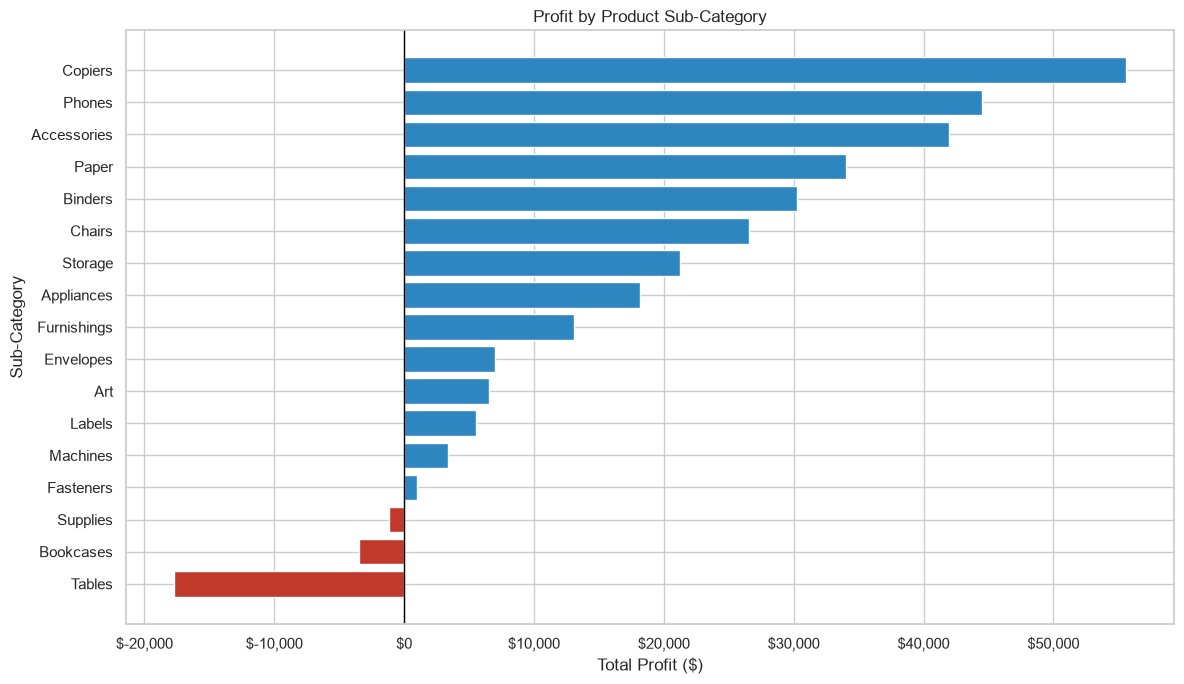

In [12]:

colors = np.where(
    subcategory_performance['Total_Profit'] < 0,
    '#c0392b',
    '#2e86c1'
)

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    subcategory_performance.index,
    subcategory_performance['Total_Profit'],
    color=colors
)

ax.axvline(0, color='black', linewidth=1)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'${x:,.0f}')
)

ax.set_title('Profit by Product Sub-Category')
ax.set_xlabel('Total Profit ($)')
ax.set_ylabel('Sub-Category')

plt.tight_layout()
plt.show()



## Discount Analysis

Evaluate how different discount levels are associated with sales, profit, and profit margins.

This analysis identifies discount groups with positive and negative aggregate profitability. It does not establish a causal relationship between discounts and profit.


In [13]:

discount_analysis = df.groupby('Discount').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Row_Profit=('Profit', 'mean'),
    Transaction_Rows=('Order ID', 'size'),
    Unique_Orders=('Order ID', 'nunique')
).reset_index()

discount_analysis['Profit_Margin'] = (
    discount_analysis['Total_Profit'] /
    discount_analysis['Total_Sales']
) * 100

discount_analysis['Discount_Label'] = (
    discount_analysis['Discount']
    .mul(100)
    .round()
    .astype(int)
    .astype(str) + '%'
)

discount_analysis.round(2)


,Discount,Total_Sales,Total_Profit,Average_Row_Profit,Transaction_Rows,Unique_Orders,Profit_Margin,Discount_Label
0,0.00,"1,087,908.47","320,987.60",66.90,4798,2644,29.51,0%
1,0.10,"54,369.35","9,029.18",96.06,94,89,16.61,10%
2,0.15,"27,558.52","1,418.99",27.29,52,51,5.15,15%
3,0.20,"764,594.37","90,337.31",24.70,3657,2407,11.82,20%
4,0.30,"103,226.66","-10,369.28",-45.68,227,211,-10.05,30%
5,0.32,"14,493.46","-2,391.14",-88.56,27,27,-16.50,32%
6,0.40,"116,417.78","-23,057.05",-111.93,206,185,-19.81,40%
7,0.45,"5,484.97","-2,493.11",-226.65,11,10,-45.45,45%
8,0.50,"58,918.54","-20,506.43",-310.70,66,64,-34.80,50%
9,0.60,"6,644.70","-5,944.66",-43.08,138,127,-89.46,60%


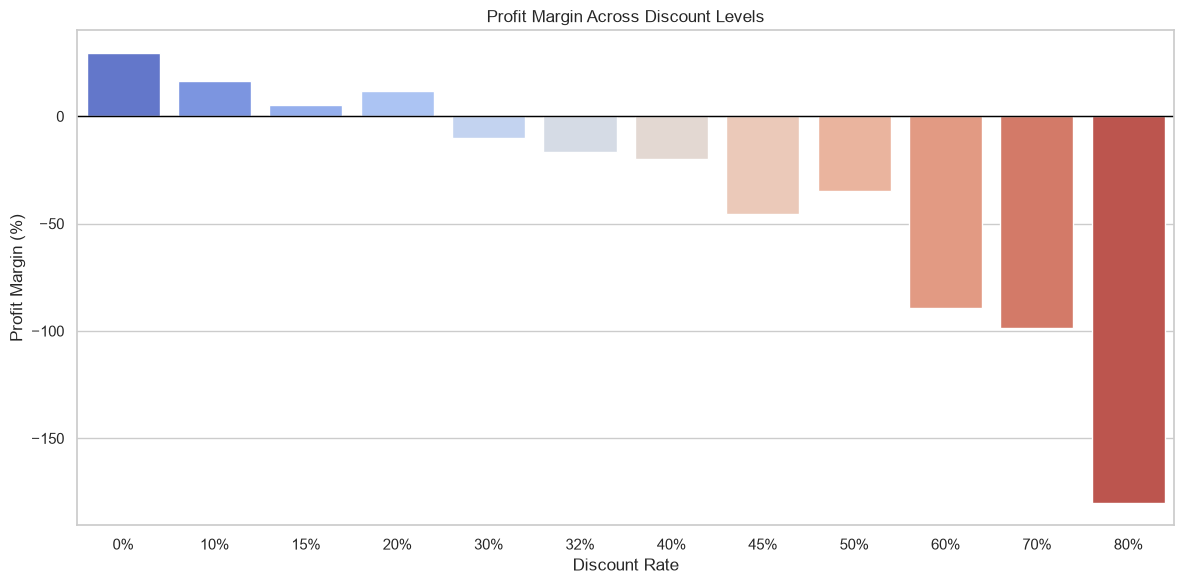

In [14]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=discount_analysis,
    x='Discount_Label',
    y='Profit_Margin',
    hue='Discount_Label',
    palette='coolwarm',
    legend=False
)

plt.axhline(0, color='black', linewidth=1)
plt.title('Profit Margin Across Discount Levels')
plt.xlabel('Discount Rate')
plt.ylabel('Profit Margin (%)')

plt.tight_layout()
plt.show()


In [15]:

high_discount_analysis = (
    df[df['Discount'] >= 0.30]
    .groupby('Sub-Category')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Transaction_Rows=('Sales', 'size')
    )
    .sort_values('Total_Profit')
)

high_discount_analysis.round(2)


,Total_Sales,Total_Profit,Transaction_Rows
Sub-Category,,,
Binders,"36,140.61","-38,510.50",613
Tables,"89,956.54","-30,698.22",176
Machines,"76,839.11","-29,555.35",53
Bookcases,"28,544.00","-11,097.76",70
Appliances,"3,382.53","-8,629.64",67
Chairs,"70,005.50","-6,737.12",158
Phones,"34,337.35","-6,385.79",109
Furnishings,"6,644.70","-5,944.66",138
Copiers,"16,919.80","2,182.98",9



## Time-Based Sales Analysis

Analyze monthly sales patterns and compare yearly performance to identify trends and seasonal variations.


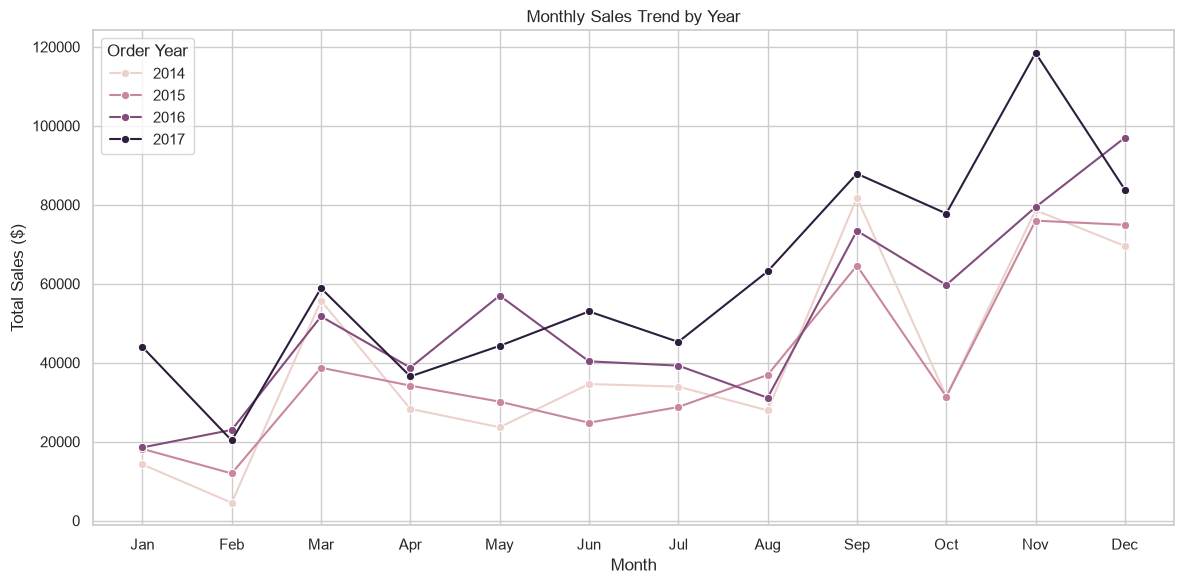

In [16]:

monthly_trend = df.groupby(
    ['Order Year', 'Order Month']
).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).reset_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_trend,
    x='Order Month',
    y='Total_Sales',
    hue='Order Year',
    marker='o'
)

plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.title('Monthly Sales Trend by Year')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')

plt.tight_layout()
plt.show()


In [17]:

yearly_performance = df.groupby('Order Year').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order ID', 'nunique')
)

yearly_performance['Profit_Margin'] = (
    yearly_performance['Total_Profit'] /
    yearly_performance['Total_Sales']
) * 100

yearly_performance['Sales_Growth_%'] = (
    yearly_performance['Total_Sales'].pct_change()
) * 100

yearly_performance.round(2)


,Total_Sales,Total_Profit,Total_Orders,Profit_Margin,Sales_Growth_%
Order Year,,,,,
2014,"484,247.50","49,543.97",969,10.23,NaN
2015,"470,532.51","61,618.60",1038,13.10,-2.83
2016,"609,205.60","81,795.17",1315,13.43,29.47
2017,"733,215.26","93,439.27",1687,12.74,20.36



## Regional Performance Analysis

Compare regional sales, profitability, order volume, and profit margins to identify differences in business performance.


In [18]:

region_performance = df.groupby('Region').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Orders=('Order ID', 'nunique')
)

region_performance['Profit_Margin'] = (
    region_performance['Total_Profit'] /
    region_performance['Total_Sales']
) * 100

region_performance.sort_values(
    'Total_Profit',
    ascending=False
).round(2)


,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
Region,,,,,
West,"725,457.82","108,418.45",12266,1611,14.94
East,"678,781.24","91,522.78",10618,1401,13.48
South,"391,721.90","46,749.43",6209,822,11.93
Central,"501,239.89","39,706.36",8780,1175,7.92


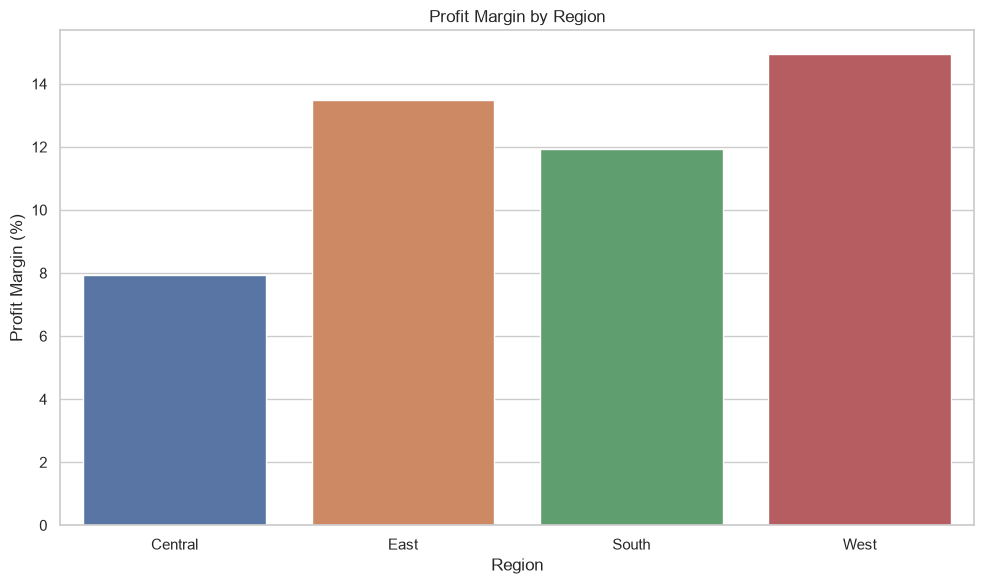

In [19]:

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=region_performance.reset_index(),
    x='Region',
    y='Profit_Margin',
    hue='Region',
    legend=False,
    ax=ax
)

ax.set_title('Profit Margin by Region')
ax.set_xlabel('Region')
ax.set_ylabel('Profit Margin (%)')

plt.tight_layout()
plt.show()



## Customer Performance Analysis

Identify the highest-revenue customers and examine their contribution to overall sales and profitability.


In [20]:

customer_analysis = df.groupby('Customer ID').agg(
    Customer_Name=('Customer Name', 'first'),
    Total_Sales=('Sales', 'sum'),
    Total_Orders=('Order ID', 'nunique'),
    Total_Profit=('Profit', 'sum')
).sort_values(
    'Total_Sales',
    ascending=False
)

customer_analysis.head(10)


,Customer_Name,Total_Sales,Total_Orders,Total_Profit
Customer ID,,,,
SM-20320,Sean Miller,"25,043.05",5,"-1,980.74"
TC-20980,Tamara Chand,"19,052.22",5,"8,981.32"
RB-19360,Raymond Buch,"15,117.34",6,"6,976.10"
TA-21385,Tom Ashbrook,"14,595.62",4,"4,703.79"
AB-10105,Adrian Barton,"14,473.57",10,"5,444.81"
KL-16645,Ken Lonsdale,"14,175.23",12,806.86
SC-20095,Sanjit Chand,"14,142.33",9,"5,757.41"
HL-15040,Hunter Lopez,"12,873.30",6,"5,622.43"
SE-20110,Sanjit Engle,"12,209.44",11,"2,650.68"


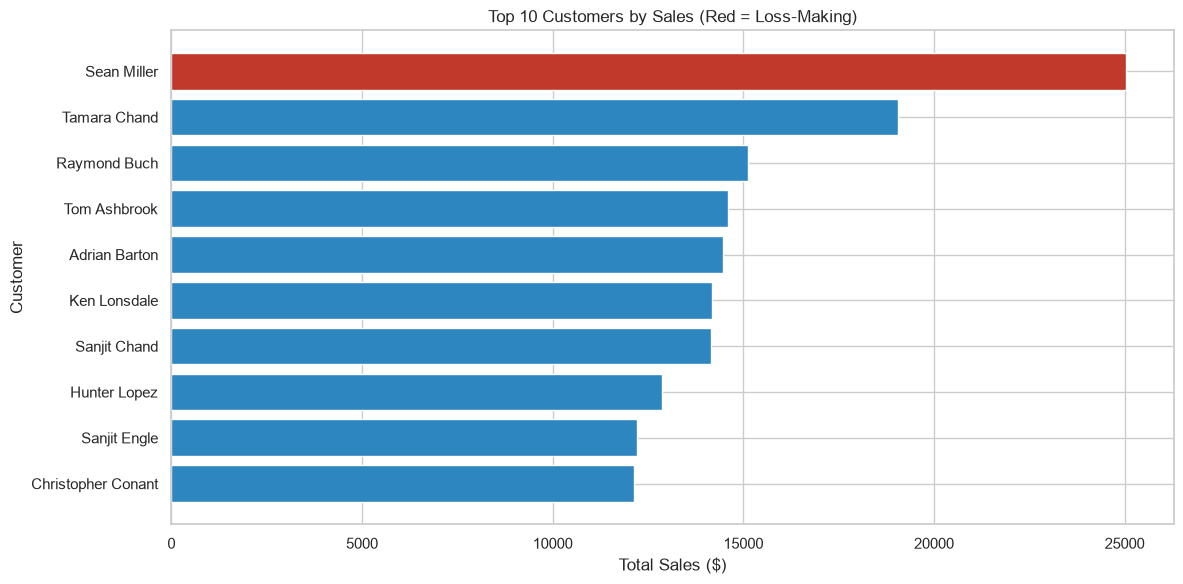

In [21]:

top_customers = customer_analysis.head(10).reset_index()

customer_colors = np.where(
    top_customers['Total_Profit'] < 0,
    '#c0392b',
    '#2e86c1'
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_customers['Customer_Name'],
    top_customers['Total_Sales'],
    color=customer_colors
)

plt.title('Top 10 Customers by Sales (Red = Loss-Making)')
plt.xlabel('Total Sales ($)')
plt.ylabel('Customer')
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


In [22]:
    
total_customer_sales = customer_analysis['Total_Sales'].sum()

top_10_percent_count = max(
    1,
    int(np.ceil(len(customer_analysis) * 0.10))
)

top_10_percent_sales = (
    customer_analysis.head(top_10_percent_count)['Total_Sales'].sum()
)

customer_contribution = (
    top_10_percent_sales / total_customer_sales
) * 100

print("Total Customers:", len(customer_analysis))
print(
    f"Top 10% Customers' Sales Contribution: "
    f"{customer_contribution:.2f}%"
)

print(
    "Unprofitable Customers:",
    (customer_analysis['Total_Profit'] < 0).sum()
)


Total Customers: 793
Top 10% Customers' Sales Contribution: 30.88%
Unprofitable Customers: 155



## SQL Analysis Using SQLite

SQL is used to independently analyze category, regional, and sub-category performance.

The database is created in memory for this notebook session.


In [23]:

conn = sqlite3.connect(':memory:')

df.to_sql(
    'sales',
    conn,
    index=False,
    if_exists='replace'
)

print("SQLite database and sales table created successfully.")


SQLite database and sales table created successfully.


In [24]:

query = """
SELECT
    Category,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    ROUND(100.0 * SUM(Profit) / SUM(Sales), 2) AS Profit_Margin
FROM sales
GROUP BY Category
ORDER BY Total_Sales DESC;
"""

sql_category = pd.read_sql_query(query, conn)
sql_category


,Category,Total_Sales,Total_Profit,Profit_Margin
0,Technology,"836,154.03","145,454.95",17.40
1,Furniture,"741,999.80","18,451.27",2.49
2,Office Supplies,"719,047.03","122,490.80",17.04


In [25]:

query = """
SELECT
    Region,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    COUNT(DISTINCT "Order ID") AS Total_Orders
FROM sales
GROUP BY Region
ORDER BY Total_Profit DESC;
"""

sql_region = pd.read_sql_query(query, conn)
sql_region


,Region,Total_Sales,Total_Profit,Total_Orders
0,West,"725,457.82","108,418.45",1611
1,East,"678,781.24","91,522.78",1401
2,South,"391,721.91","46,749.43",822
3,Central,"501,239.89","39,706.36",1175


In [26]:

query = """
WITH subcategory_summary AS (
    SELECT
        Category,
        "Sub-Category" AS Sub_Category,
        SUM(Sales) AS Sales,
        SUM(Profit) AS Profit
    FROM sales
    GROUP BY Category, "Sub-Category"
)

SELECT
    Category,
    Sub_Category,
    ROUND(Sales, 2) AS Total_Sales,
    ROUND(Profit, 2) AS Total_Profit,
    ROUND(100.0 * Profit / Sales, 2) AS Profit_Margin,
    RANK() OVER (
        PARTITION BY Category
        ORDER BY Profit DESC
    ) AS Rank_In_Category
FROM subcategory_summary
ORDER BY Category, Rank_In_Category;
"""

sql_subcategory = pd.read_sql_query(query, conn)
sql_subcategory


,Category,Sub_Category,Total_Sales,Total_Profit,Profit_Margin,Rank_In_Category
0,Furniture,Chairs,"328,449.10","26,590.17",8.10,1
1,Furniture,Furnishings,"91,705.16","13,059.14",14.24,2
2,Furniture,Bookcases,"114,880.00","-3,472.56",-3.02,3
3,Furniture,Tables,"206,965.53","-17,725.48",-8.56,4
4,Office Supplies,Paper,"78,479.21","34,053.57",43.39,1
5,Office Supplies,Binders,"203,412.73","30,221.76",14.86,2
6,Office Supplies,Storage,"223,843.61","21,278.83",9.51,3
7,Office Supplies,Appliances,"107,532.16","18,138.01",16.87,4
8,Office Supplies,Envelopes,"16,476.40","6,964.18",42.27,5
9,Office Supplies,Art,"27,118.79","6,527.79",24.07,6



## Key Business Insights

The following observations should be written using the actual results generated by the notebook.

### 1. Category Performance
Compare category sales and profit margins. Identify categories with strong revenue but weak profitability.

### 2. Sub-Category Profitability
Highlight loss-making sub-categories and investigate their sales, profit, and margin patterns.

### 3. Discount Analysis
Identify discount levels associated with negative aggregate profit. Examine whether losses are concentrated in particular sub-categories.

### 4. Regional Performance
Compare regional profit margins instead of relying only on total sales.

### 5. Customer Contribution
Evaluate how much of total sales is generated by the top 10% of customers. Identify high-revenue customers with negative total profit.



## Conclusion

This project explored retail sales performance through Python, Pandas, data visualization, and SQL.
The analysis covered product categories, sub-categories, discounts, monthly and yearly trends, regional performance, and customer contribution.

The findings can help identify areas requiring further investigation, particularly low-margin products and discount groups with negative aggregate profitability.

## Business Recommendations

- Review pricing and discount strategies for loss-making sub-categories.
- Monitor regional profit margins alongside sales.
- Investigate customers generating high revenue but negative profit.
- Evaluate seasonal sales patterns when planning inventory and promotions.

## Limitations

- The dataset is a sample retail dataset, not verified real-world company data.
- Observational analysis cannot establish that discounts directly cause profit losses.
- Customer and product performance may be influenced by order size, product mix, and other factors.
- Further analysis is needed before making operational decisions.


In [27]:

print("========== FINAL PROJECT SUMMARY ==========")

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Quantity: {total_quantity:,}")
print(f"Overall Profit Margin: {profit_margin:.2f}%")

print("\nMost Profitable Category:")
print(category_performance['Total_Profit'].idxmax())

print("\nLowest-Profit Category:")
print(category_performance['Total_Profit'].idxmin())

print("\nMost Profitable Sub-Category:")
print(subcategory_performance['Total_Profit'].idxmax())

print("\nLowest-Profit Sub-Category:")
print(subcategory_performance['Total_Profit'].idxmin())

print("\nHighest-Profit Region:")
print(region_performance['Total_Profit'].idxmax())

print("============================================")


========== FINAL PROJECT SUMMARY ==========
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Total Quantity: 37,873
Overall Profit Margin: 12.47%

Most Profitable Category:
Technology

Lowest-Profit Category:
Furniture

Most Profitable Sub-Category:
Copiers

Lowest-Profit Sub-Category:
Tables

Highest-Profit Region:
West


In [28]:

conn.close()
